In [1]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

In [2]:
pth = os.path.join('..', '..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'development', 'modeling')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_out = os.path.join(pth, 'figures', 'mesencoder', 'rRNAModifications')

In [3]:
fn = os.path.join(pth_feat, 'union.csv')
g = pd.read_csv(fn).mmusculus.drop_duplicates()

In [4]:
labels_dict = {
    'Epiblast'                   : 'Epi',
    'Posterior Epiblast'         : 'pEpi',
    'Lateral Plate Mesoderm'     : 'LPM',
    'Nascent Endothelium'        : 'NE',
    'Neuromesodermal Progenitor' : 'NMP',
    'Presomitic Mesoderm'        : 'PSM',
    'Somite'                     : 'Somite',
    'Premigratory Neural Crest'  : 'pmNC',
    'Migratory Neural Crest'     : 'mNC',
    'Neuroglial Progenitors'     : 'NGP',
    'Cranial Mesenchyme'         : 'CM'}
celltypes = list(labels_dict.keys())

In [5]:
adata = sc.read_h5ad(os.path.join(pth_in, 'trajectories.h5ad'))
adata = adata[adata.obs.celltype.isin(celltypes), g].copy()
adata.X = np.asarray(adata.X.toarray() - adata.X.mean(axis = 1))
adata

AnnData object with n_obs × n_vars = 14344 × 237
    obs: 'sample', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'celltype', 't', 'total_counts_ribo', 'pct_counts_ribo', 'T+ Sox2+', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'RNA_snn_res.0.1', 'seurat_clusters', 'age', 'RNA_snn_res.0.5', 'ident', 'velocity_self_transition', 'celltype_original', 'source'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap', 'X_umap_traj', 'velocity_umap'
    layers: 'logcounts', 'scaled'

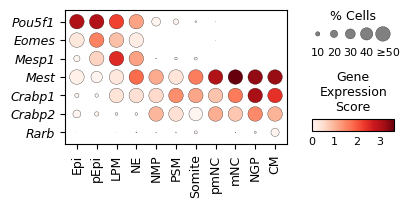

In [6]:
g_plt = ['Pou5f1', 'Eomes', 'Mesp1', 'Mest',
         'Crabp1', 'Crabp2', 'Rarb']

# expression dotplot
fs1, fs2 = 9, 8
dp = sc.pl.dotplot(adata, g_plt, 'celltype',
                   categories_order = celltypes,
                   dot_max = .5, vmin = 0,
                   figsize = (4.25, 1.75),
                   return_fig = True,
                   swap_axes = True,
                   show = False)

dp.style(largest_dot = 110,
         x_padding = .6,
         y_padding = .65)
dp.legend(width = 1.15)

ax = dp.get_axes()
ax_main = ax['mainplot_ax']
ax_size = ax['size_legend_ax']
cax = ax['color_legend_ax']

ax_size.set_title('% Cells', size = fs1, pad = -7)
ax_size.tick_params('x', size = 0, labelsize = fs2, pad = 4)
ax_size.set_xticklabels(['10', '20', '30', '40', '   ≥50'])
cax.set_title('Gene\nExpression\nScore', size = fs1, pad = 6)
cax.set_xticks([0, 1, 2, 3])
cax.tick_params('x', size = 0, labelsize = fs2, pad = 4)

pos_main = ax_main.get_position()
pos_size = ax_size.get_position()
pos_color = cax.get_position()

ax_size.set_position([pos_size.x0,
                      pos_main.y0 + .76 * pos_main.height,
                      pos_size.width,
                      pos_size.height])

cax.set_position([pos_color.x0,
                  pos_main.y0 + .1 * pos_main.height,
                  pos_color.width,
                  1.25 * pos_color.height])

ax_main.set_xticklabels([labels_dict[lbl.get_text()] for
                         lbl in ax_main.get_xticklabels()],
                        fontsize = fs1)

ax_main.set_yticklabels(ax_main.get_yticklabels(),
                        fontsize = fs1,
                        fontstyle = 'italic')

fn = os.path.join(pth_out, 'expression.pdf')
plt.savefig(fn, bbox_inches = 'tight')